In [1]:
!pip install xgboost
!pip install lightgbm
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.3 MB/s eta 0:00:00


In [4]:
# COLON Cancer with ONLY researched biomarkers
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, ExtraTreesClassifier)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Load
df = pd.read_csv("colon_cancer_extended.csv")

# ── Core CRC biomarkers only ───────────────────────────────
core_features = [
    "Age", "BMI", "Obesity", "Family_History",
    "Diet_Red_Meat", "Fruit_Veg_Intake",
    "Physical_Activity", "Calcium_Intake",

]
'''
"Alcohol_Use",        # ← strong CRC risk factor
    "H_Pylori_Infection",  # ← confirmed CRC/gastric risk factor
    "Diet_Salted_Processed"  # ← adds dietary pattern signal

core_features = [
    "Age", "Gender", "Smoking", "Alcohol_Use", "Obesity",
    "Family_History", "Diet_Red_Meat", "Diet_Salted_Processed",
    "Fruit_Veg_Intake", "Physical_Activity", "Air_Pollution",
    "Occupational_Hazards", "BRCA_Mutation", "H_Pylori_Infection",
    "Calcium_Intake", "BMI", "Physical_Activity_Level"
]
'''

target_col = "Risk_Level"

X = df[core_features]
y = LabelEncoder().fit_transform(df[target_col])
le = LabelEncoder().fit(df[target_col])

print(f"Features: {core_features}")
print(f"Shape: {X.shape}")
print(df[target_col].value_counts())

# Split + Scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Decision Tree":       DecisionTreeClassifier(random_state=42, max_depth=6,
                                                   min_samples_leaf=10,
                                                   class_weight='balanced'),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42,
                                                   max_depth=10, min_samples_leaf=5,
                                                   class_weight='balanced'),
    "Extra Trees":         ExtraTreesClassifier(n_estimators=200, random_state=42,
                                                max_depth=10, min_samples_leaf=5,
                                                class_weight='balanced'),
    "AdaBoost":            AdaBoostClassifier(n_estimators=150, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=150, random_state=42,
                                                       max_depth=4, learning_rate=0.05,
                                                       subsample=0.8),
    "SVM (RBF Kernel)":    SVC(kernel='rbf', probability=True, random_state=42,
                               class_weight='balanced'),
    "XGBoost":             XGBClassifier(n_estimators=150, random_state=42,
                                          max_depth=4, learning_rate=0.05,
                                          subsample=0.8, reg_alpha=0.1,
                                          reg_lambda=1.0, eval_metric='logloss'),
    "LightGBM":            LGBMClassifier(n_estimators=150, random_state=42,
                                           max_depth=4, learning_rate=0.05,
                                           reg_alpha=0.5, reg_lambda=2.0,
                                           min_child_samples=30,
                                           class_weight='balanced'),
    "CatBoost":            CatBoostClassifier(verbose=0, random_state=42,
                                               depth=4, learning_rate=0.05,
                                               l2_leaf_reg=5.0)
}

# Train and evaluate
results     = {}
predictions = {}

print("\n=== Results: Core CRC Features Only ===")
print(f"{'Model':<25} {'Test Acc':>10} {'Train Acc':>10} {'Gap':>8} {'Status':>10}")
print("-" * 68)

for name, model in models.items():
    if name == "XGBoost":
        from sklearn.utils.class_weight import compute_sample_weight
        sw = compute_sample_weight(class_weight='balanced', y=y_train)
        model.fit(X_train, y_train, sample_weight=sw)
    else:
        model.fit(X_train, y_train)

    y_pred      = model.predict(X_test)
    test_acc    = accuracy_score(y_test, y_pred)
    train_acc   = accuracy_score(y_train, model.predict(X_train))
    gap         = train_acc - test_acc
    status      = "⚠️ Overfit" if gap > 0.15 else "⚡ Slight" if gap > 0.05 else "✓ Good"

    results[name]     = test_acc
    predictions[name] = y_pred
    print(f"{name:<25} {test_acc:>10.4f} {train_acc:>10.4f} {gap:>8.4f} {status:>10}")

# Best model report
results_df      = pd.DataFrame(list(results.items()),
                                columns=["Model", "Accuracy"]).sort_values(
                                by="Accuracy", ascending=False)
best_model_name = results_df.iloc[0]['Model']

print(f"\n🏁 Best Model: {best_model_name} — {results_df.iloc[0]['Accuracy']:.4f}")
print(f"\n=== Classification Report: {best_model_name} ===")
print(classification_report(y_test, predictions[best_model_name],
                             target_names=le.classes_))

Features: ['Age', 'BMI', 'Obesity', 'Family_History', 'Diet_Red_Meat', 'Fruit_Veg_Intake', 'Physical_Activity', 'Calcium_Intake']
Shape: (4110, 8)
Risk_Level
Medium    3275
Low        550
High       285
Name: count, dtype: int64

=== Results: Core CRC Features Only ===
Model                       Test Acc  Train Acc      Gap     Status
--------------------------------------------------------------------
Logistic Regression           0.2822     0.3114   0.0292     ✓ Good
Decision Tree                 0.3102     0.3604   0.0502   ⚡ Slight
Random Forest                 0.7056     0.9377   0.2321 ⚠️ Overfit
Extra Trees                   0.5365     0.7783   0.2418 ⚠️ Overfit
AdaBoost                      0.8017     0.7956  -0.0061     ✓ Good
Gradient Boosting             0.7968     0.8187   0.0219     ✓ Good
SVM (RBF Kernel)              0.3723     0.4550   0.0827   ⚡ Slight
XGBoost                       0.4830     0.6673   0.1843 ⚠️ Overfit
[LightGBM] [Info] Auto-choosing row-wise multi-th

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM                      0.4428     0.6064   0.1636 ⚠️ Overfit
CatBoost                      0.8005     0.8050   0.0046     ✓ Good

🏁 Best Model: AdaBoost — 0.8017

=== Classification Report: AdaBoost ===
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        59
         Low       0.00      0.00      0.00       104
      Medium       0.80      1.00      0.89       659

    accuracy                           0.80       822
   macro avg       0.27      0.33      0.30       822
weighted avg       0.64      0.80      0.71       822



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


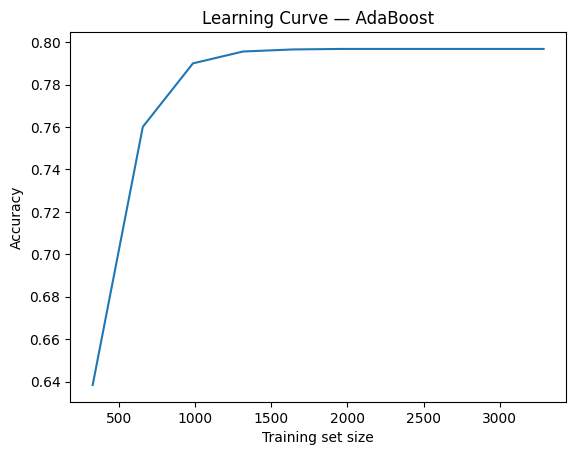

In [ ]:
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
import matplotlib.pyplot as plt
import numpy as np

train_sizes, train_scores, test_scores = learning_curve(
    models["AdaBoost"], X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5, scoring='accuracy'
)

plt.plot(train_sizes, test_scores.mean(axis=1))
plt.xlabel("Training set size")
plt.ylabel("Accuracy")
plt.title("Learning Curve — AdaBoost")
plt.show()

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neural_network import MLPClassifier

# Load
df = pd.read_csv("colon_cancer_extended.csv")

# Features
core_features = [
    "Age", "BMI", "Obesity", "Family_History",
    "Diet_Red_Meat", "Fruit_Veg_Intake",
    "Physical_Activity", "Calcium_Intake"
]

target_col = "Risk_Level"

le = LabelEncoder().fit(df[target_col])
X  = df[core_features]
y  = le.transform(df[target_col])

print(f"Features: {core_features}")
print(f"Shape: {X.shape}")
print(df[target_col].value_counts())

# Split + Scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# MLP models — different architectures
mlp_models = {
    "MLP (64-32)":       MLPClassifier(
                             hidden_layer_sizes=(64, 32),
                             activation='relu',
                             max_iter=500,
                             random_state=42,
                             early_stopping=True,
                             validation_fraction=0.1),
    "MLP (128-64-32)":   MLPClassifier(
                             hidden_layer_sizes=(128, 64, 32),
                             activation='relu',
                             max_iter=500,
                             random_state=42,
                             early_stopping=True,
                             validation_fraction=0.1),
    "MLP (256-128-64)":  MLPClassifier(
                             hidden_layer_sizes=(256, 128, 64),
                             activation='relu',
                             max_iter=500,
                             random_state=42,
                             early_stopping=True,
                             validation_fraction=0.1),
}

# Train and evaluate
print("\n=== MLP Results: Core CRC Features ===")
print(f"{'Model':<22} {'Test Acc':>10} {'Train Acc':>10} {'Gap':>8} {'Status':>10}")
print("-" * 65)

results     = {}
predictions = {}

for name, model in mlp_models.items():
    model.fit(X_train, y_train)

    y_pred    = model.predict(X_test)
    test_acc  = accuracy_score(y_test, y_pred)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    gap       = train_acc - test_acc
    status    = ("⚠️ Overfit" if gap > 0.15 else
                 "⚡ Slight"  if gap > 0.05 else "✓ Good")

    results[name]     = test_acc
    predictions[name] = y_pred

    print(f"{name:<22} {test_acc:>10.4f} {train_acc:>10.4f} "
          f"{gap:>8.4f} {status:>10}")

# Best model
best = max(results, key=results.get)
print(f"\n🏁 Best MLP: {best} — {results[best]:.4f}")

print(f"\n=== Classification Report: {best} ===")
print(classification_report(y_test, predictions[best],
                             target_names=le.classes_))

Features: ['Age', 'BMI', 'Obesity', 'Family_History', 'Diet_Red_Meat', 'Fruit_Veg_Intake', 'Physical_Activity', 'Calcium_Intake']
Shape: (4110, 8)
Risk_Level
Medium    3275
Low        550
High       285
Name: count, dtype: int64

=== MLP Results: Core CRC Features ===
Model                    Test Acc  Train Acc      Gap     Status
-----------------------------------------------------------------
MLP (64-32)                0.8017     0.7956  -0.0061     ✓ Good
MLP (128-64-32)            0.8017     0.7956  -0.0061     ✓ Good
MLP (256-128-64)           0.8017     0.7956  -0.0061     ✓ Good

🏁 Best MLP: MLP (64-32) — 0.8017

=== Classification Report: MLP (64-32) ===
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        59
         Low       0.00      0.00      0.00       104
      Medium       0.80      1.00      0.89       659

    accuracy                           0.80       822
   macro avg       0.27      0.33      0.30       822
w

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
